# Chapter 16 · Convergence in law: interactive demos

Companion to Chapter 16 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/16-convergence-in-law.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.inlaw import (binomial_charfun, binomial_poisson_distances, ecdf, empirical_charfun,
                             kolmogorov_distance_sample, le_cam_bound, normal_charfun, one_over_n_cdf,
                             poisson_charfun, sample_scaled_max, scaled_max_cdf, sum_counterexample)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Distribution functions and characteristic functions

Convergence in law is convergence of the distribution functions $F_n(x)\to F(x)$ at every continuity point $x$ of $F$
(Theorem 16.7), or, equivalently, convergence of the characteristic functions $\Phi_n(t)\to\Phi(t)$ for every $t$ (Lévy's
theorem 16.11). Four sequences:

* **$X_n=\frac1n$** (Example 16.8): $F_n(0)=0$ for every $n$, while $F(0)=1$. The gap at $x=0$ never closes, but $0$ is a
  discontinuity point of $F$, so the criterion ignores it. The Kolmogorov distance $\sup_x|F_n(x)-F(x)|$ stays $1$.
* **$Z_n=n(1-\max_{i\le n}U_i)$** (Example 16.18): $F_n(x)=1-(1-\frac xn)^n\to1-e^{-x}$, uniformly, at rate $\frac1n$.
* **$X_n\sim B(n,\frac\lambda n)$** (Example 16.19), with $\lambda=2$: the limit is $\mathcal P(2)$.
* **$X_n\sim\mathcal N(0,n)$** (Exercise 16.3): $F_n(x)\to\frac12$ for every $x$, which is no distribution function, and
  $\Phi_n(t)=e^{-nt^2/2}\to\mathbf 1_{\{t=0\}}$, which is not continuous at $0$ (Remark 16.12): no convergence in law.

Left: $F_n$ (blue), the limit (dashed), and the empirical distribution function of $2000$ simulated values of $X_n$ (gold
steps). Right: the real part of $\Phi_n$ and of the limit (for $Z_n$, $\Phi_n$ is estimated from the simulated values).

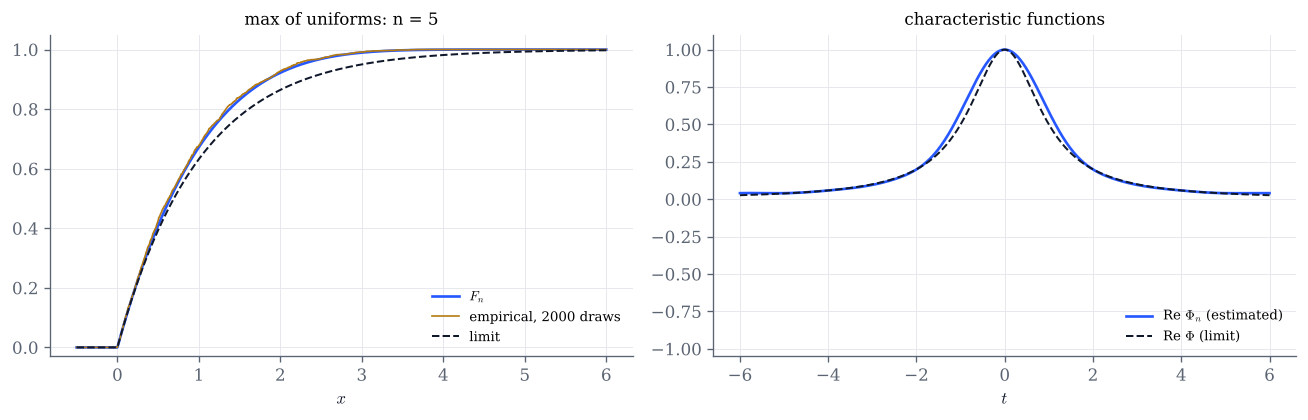

Kolmogorov distance sup_x |F_n(x) - F(x)| = 0.05799


In [3]:
EXAMPLES = ["1/n", "max of uniforms", "binomial -> Poisson", "N(0, n)"]

def law_demo(example="max of uniforms", n=5, seed=2026):
    rng = np.random.default_rng(seed)
    t = np.linspace(-6, 6, 601)
    if example == "1/n":
        x = np.linspace(-1, 1, 2001)
        Fn, F = one_over_n_cdf(n, x), one_over_n_cdf(np.inf, x)
        sample = np.full(2000, 1.0 / n)
        Pn, P = np.exp(1j * t / n), np.ones_like(t, dtype=complex)
        dist = 1.0                                   # F_n(0) = 0, F(0) = 1
    elif example == "max of uniforms":
        x = np.linspace(-0.5, 6, 2001)
        Fn, F = scaled_max_cdf(n, x), scaled_max_cdf(np.inf, x)
        sample = sample_scaled_max(n, 2000, seed=rng)
        Pn, P = empirical_charfun(sample, t), 1 / (1 - 1j * t)
        dist = float(np.max(np.abs(Fn - F)))
    elif example == "binomial -> Poisson":
        lam = 2.0
        n = max(n, 2)
        x = np.linspace(-0.5, 10, 2101)
        Fn, F = stats.binom.cdf(x, n, lam / n), stats.poisson.cdf(x, lam)
        sample = rng.binomial(n, lam / n, 2000)
        Pn, P = binomial_charfun(n, lam / n, t), poisson_charfun(lam, t)
        dist = binomial_poisson_distances(n, lam)[1]
    else:
        x = np.linspace(-10, 10, 2001)
        Fn, F = stats.norm.cdf(x, scale=math.sqrt(n)), np.full_like(x, 0.5)
        sample = rng.normal(0, math.sqrt(n), 2000)
        Pn, P = normal_charfun(n, t), (t == 0).astype(complex)
        dist = float("nan")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    a1.plot(x, Fn, color=COBALT, label="$F_n$")
    a1.plot(x, ecdf(sample, x), color=GOLD, lw=1.0, label="empirical, 2000 draws")
    a1.plot(x, F, color=INK, ls="--", lw=1.2, label="limit" if example != "N(0, n)" else r"$\lim F_n=\frac{1}{2}$")
    a1.set(xlabel="$x$", ylim=(-0.03, 1.05), title=f"{example}: n = {n}")
    a1.legend(loc="lower right", fontsize=8)
    a2.plot(t, Pn.real, color=COBALT, label=r"Re $\Phi_n$" + (" (estimated)" if example == "max of uniforms" else ""))
    if example == "N(0, n)":
        a2.plot(t[t != 0], np.zeros((t != 0).sum()), color=INK, ls="--", lw=1.2, label=r"$\lim\Phi_n$")
        a2.plot([0], [1], "o", color=INK, ms=5)
    else:
        a2.plot(t, P.real, color=INK, ls="--", lw=1.2, label=r"Re $\Phi$ (limit)")
    a2.set(xlabel="$t$", ylim=(-1.05, 1.1), title="characteristic functions")
    a2.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    plt.show()
    if example == "N(0, n)":
        print(f"P(|X_n| <= 1) = {2 * stats.norm.cdf(1 / math.sqrt(n)) - 1:.4f}: the mass escapes to infinity")
    else:
        print(f"Kolmogorov distance sup_x |F_n(x) - F(x)| = {dist:.4g}")

law_demo()

In [4]:
# Explore: for "1/n" the distance stays 1 however large n is; for the other two limits it decreases like 1/n.
interact(law_demo,
         example=Dropdown(options=EXAMPLES, value="max of uniforms", description="example"),
         n=IntSlider(value=5, min=1, max=200, step=1, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. From the binomial to the Poisson law

Example 16.19 proves $B(n,\frac\lambda n)\to\mathcal P(\lambda)$ in three ways: discrete densities, distribution functions and
characteristic functions. Left: the two discrete densities. Centre: the total variation distance
$\sup_A|\mathbb P_{X_n}(A)-\mathbb P_Y(A)|=\frac12\sum_k|\mathbb P(X_n=k)-\mathbb P(Y=k)|$ and the Kolmogorov distance
$\sup_x|F_n(x)-F_Y(x)|$, computed exactly as functions of $n$, against Le Cam's bound $\frac{\lambda^2}n$ (Exercise 16.8);
the dot marks the current $n$. Right: $|\Phi_n(t)-\Phi_Y(t)|$ on one period, below the bound $\frac{8\lambda^2}n$ of the third method
(valid for $n\ge4\lambda$).

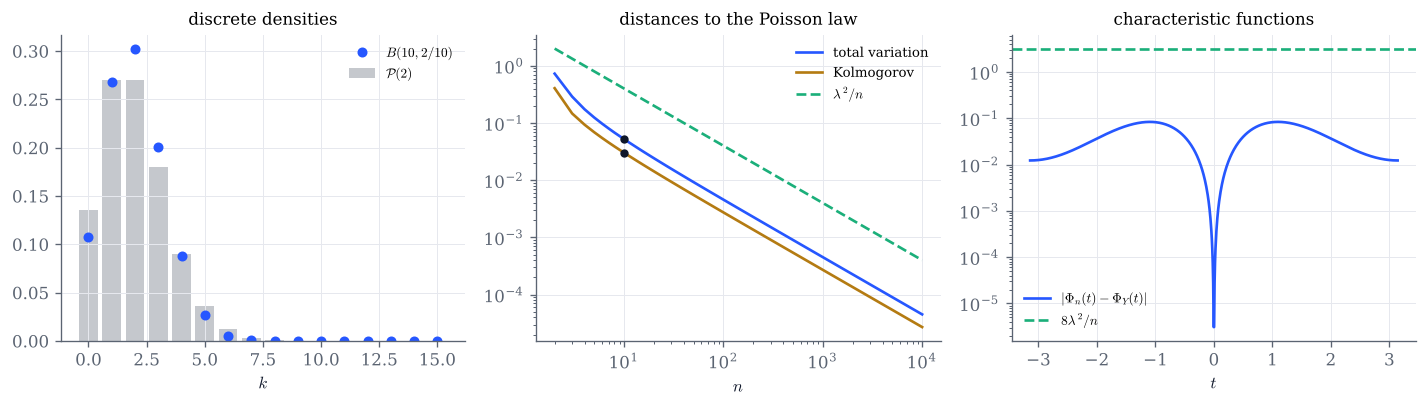

n = 10: total variation 0.0522 (n x TV = 0.5220), Kolmogorov 0.0302 (n x K = 0.3020); P(X_n <= 2) = 0.677800, P(Y <= 2) = 0.676676


In [5]:
def poisson_demo(n=10, lam=2.0):
    n = max(n, int(math.ceil(lam)))
    k = np.arange(0, int(lam + 6 * math.sqrt(lam) + 6))
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(12, 3.5))
    a1.bar(k, stats.poisson.pmf(k, lam), width=0.8, color=GREY, alpha=0.35, label=rf"$\mathcal{{P}}({lam:g})$")
    a1.plot(k, stats.binom.pmf(k, n, lam / n), "o", color=COBALT, ms=5, label=rf"$B({n},{lam:g}/{n})$")
    a1.set(xlabel="$k$", title="discrete densities")
    a1.legend(fontsize=8)
    ns = np.unique(np.round(np.logspace(math.log10(max(lam, 1)), 4, 50)).astype(int))
    ns = ns[ns >= lam]
    tv, ks = binomial_poisson_distances(ns, lam)
    a2.loglog(ns, tv, color=COBALT, label="total variation")
    a2.loglog(ns, ks, color=GOLD, label="Kolmogorov")
    a2.loglog(ns, le_cam_bound(ns, lam), color=GREEN, ls="--", label=r"$\lambda^2/n$")
    tv_n, ks_n = binomial_poisson_distances(n, lam)
    a2.plot([n, n], [tv_n, ks_n], "o", color=INK, ms=4)
    a2.set(xlabel="$n$", title="distances to the Poisson law")
    a2.legend(fontsize=8)
    t = np.linspace(-math.pi, math.pi, 800)            # an even number of points avoids t = 0, where the gap is 0
    gap = np.abs(binomial_charfun(n, lam / n, t) - poisson_charfun(lam, t))
    a3.semilogy(t, gap, color=COBALT, label=r"$|\Phi_n(t)-\Phi_Y(t)|$")
    if n >= 4 * lam:
        a3.axhline(8 * lam ** 2 / n, color=GREEN, ls="--", label=r"$8\lambda^2/n$")
    a3.set(xlabel="$t$", title="characteristic functions")
    a3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"n = {n}: total variation {tv_n:.4g} (n x TV = {n * tv_n:.4f}), Kolmogorov {ks_n:.4g} "
          f"(n x K = {n * ks_n:.4f}); P(X_n <= 2) = {stats.binom.cdf(2, n, lam / n):.6f}, "
          f"P(Y <= 2) = {stats.poisson.cdf(2, lam):.6f}")

poisson_demo()

In [6]:
# Explore: n times each distance settles to a constant (for lambda = 2: 0.451 and 2e^{-2} = 0.271), about
# ten times smaller than Le Cam's lambda^2. Try a large lambda: is the Poisson approximation still good for n = 10 lambda?
interact(poisson_demo,
         n=IntSlider(value=10, min=1, max=1000, step=1, continuous_update=False, description="n"),
         lam=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="lambda"));

## 3. Sums: marginals are not enough

In Example 16.14, $X_n,Y_n,X\sim\mathcal N(0,1)$ and $Y=-X$: then $X_n\to X$ and $Y_n\to Y$ in law, but $X+Y=0$, while
$X_n+Y_n$ has the law $\mathcal N(0,2+2\rho)$, where $\rho$ is the correlation of $X_n$ and $Y_n$ ($\rho=0$ in the notes,
where they are independent). Every choice of $\rho$ gives the same marginal laws; only $\rho=-1$ makes the sums converge to
$X+Y$ (Exercise 16.4). Left: $1000$ simulated pairs $(X_n,Y_n)$ and pairs $(X,Y)$, which lie on the line $y=-x$. Right: the
histogram of $X_n+Y_n$ against the density of $\mathcal N(0,2+2\rho)$, and the point mass of $X+Y$ at $0$. The number
$\mathbb E[\min(|X_n+Y_n|,1)]$ would tend to $0$ if $X_n+Y_n$ converged in law to $0$.

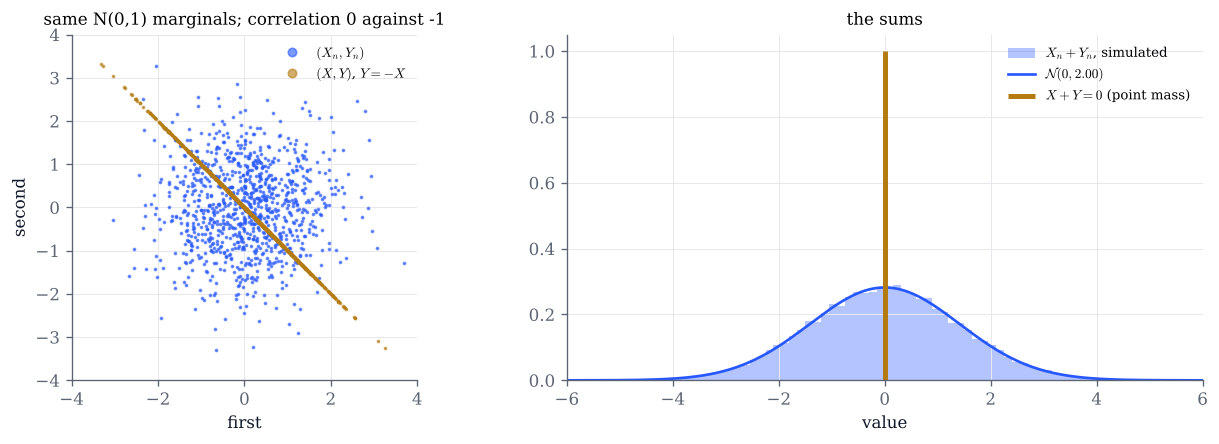

Var(X_n + Y_n) = 2.000; E[min(|X_n + Y_n|, 1)] = 0.7297 (0 for X + Y); Kolmogorov distance to the point mass at 0: 0.502


In [7]:
def sums_demo(rho=0.0, seed=2026):
    rng = np.random.default_rng(seed)
    s, z = sum_counterexample(20000, rho=rho, seed=rng)
    xn = rng.standard_normal(1000)
    yn = rho * xn + math.sqrt(max(0.0, 1 - rho ** 2)) * rng.standard_normal(1000)
    x = rng.standard_normal(1000)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    a1.plot(xn, yn, ".", color=COBALT, ms=2.5, alpha=0.6, label=r"$(X_n,Y_n)$")
    a1.plot(x, -x, ".", color=GOLD, ms=2.5, alpha=0.6, label=r"$(X,Y)$, $Y=-X$")
    a1.set(xlim=(-4, 4), ylim=(-4, 4), aspect="equal", xlabel="first", ylabel="second",
           title=f"same N(0,1) marginals; correlation {rho:g} against -1")
    a1.legend(loc="upper right", fontsize=8, markerscale=4)
    var = 2 + 2 * rho
    u = np.linspace(-6, 6, 601)
    if var > 1e-9:
        a2.hist(s, bins=80, range=(-6, 6), density=True, color=COBALT, alpha=0.35, label=r"$X_n+Y_n$, simulated")
        a2.plot(u, stats.norm.pdf(u, scale=math.sqrt(var)), color=COBALT, label=rf"$\mathcal{{N}}(0,{var:.2f})$")
    a2.vlines(0, 0, 1, color=GOLD, lw=3, label=r"$X+Y=0$ (point mass)")
    a2.set(xlim=(-6, 6), ylim=(0, 1.05), xlabel="value", title="the sums")
    a2.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.show()
    d0 = kolmogorov_distance_sample(s, lambda v: (v >= 0) * 1.0, lambda v: (v > 0) * 1.0)
    print(f"Var(X_n + Y_n) = {var:.3f}; E[min(|X_n + Y_n|, 1)] = {np.mean(np.minimum(np.abs(s), 1)):.4f} "
          f"(0 for X + Y); Kolmogorov distance to the point mass at 0: {d0:.3f}")

sums_demo()

In [8]:
# Explore: move rho towards -1. The variance 2 + 2 rho and E[min(|S|, 1)] go to 0, but the Kolmogorov distance
# to the point mass stays near 1/2: the limit has its only discontinuity at 0, where nothing is required.
interact(sums_demo,
         rho=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.01, continuous_update=False, description="rho"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, choose "1/n" and move $n$: why is the Kolmogorov distance always $1$, although $X_n\to0$ in law?
- In section 1, choose "max of uniforms" with $n=1$: what is the law of $Z_1$? Compare the estimated characteristic
  function with that of $\mathrm{Exp}(1)$, $\frac1{1-it}$, as $n$ grows.
- In section 1, choose "N(0, n)": where is the limit of $\Phi_n$ discontinuous, and what happens to $F_n$?
- In section 2, find the smallest $n$ for which the total variation distance from $\mathcal P(2)$ is below $0.01$; then
  compare with what Le Cam's bound guarantees.
- In section 3, put $\rho=-0.99$: is $X_n+Y_n$ close to $X+Y$ in law? Which number in the printout tells you so, and which
  one does not?